# 06 데이터 구성 — 명령어 10개 + "명령 아님" (11개 클래스)

설계: `설계결정_11클래스.md`. 이 노트북은 학습하지 않고, 어떤 녹음을 어느 묶음·클래스로 쓸지 정해 `splits_11class.csv`로 저장합니다. 이후 노트북은 이 목록만 읽습니다(목록에는 파일 경로만 있어 저장소에 올려도 됨).

| 무리(group) | 내용 | 정답(label) | 학습 | 검증 | 시험 |
|---|---|---|---|---|---|
| command | yes, no, up, down, left, right, on, off, stop, go | 단어 그대로 | 전부 | 전부 | 전부 |
| seen_other | 숫자 10개 + 보조 단어 10개 | other | 단어마다 같은 수로 줄여 씀 | 전부 | 전부 |
| unseen_other | backward, follow, forward, learn, visual | other | 안 씀 | 안 씀 | 전부 |
| noise | 배경 잡음 파일 6개의 1초 구간 | other | 앞 80% 구간에서 무작위로 자름 | 다음 10% | 마지막 10% |

- 단어 녹음은 공식 목록(validation_list, testing_list)을 그대로 따릅니다(화자 기준 분할).
- 잡음은 파일마다 시간 순서로 나눠, 같은 잡음 구간이 학습과 시험에 함께 들어가지 않게 합니다. 음량(gain)을 낮춰 조용한 무음부터 원래 크기의 잡음까지 섞습니다.
- 시험 묶음은 목록만 만들고 이 노트북에서 평가에 쓰지 않습니다.

In [1]:
# 셀 1. 설정과 버전
import os, sys, random, collections
import numpy as np
import pandas as pd
import torch
import torchaudio
import soundfile as sf
import matplotlib.pyplot as plt

SMOKE = False                 # True면 결과 숫자는 쓰지 않음 (이 노트북은 가벼워 SMOKE가 거의 필요 없음)
SEED = 0
DATA_ROOT = "data"
OUT_CSV = "splits_11class.csv"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
UNSEEN = ["backward", "follow", "forward", "learn", "visual"]     # README의 핵심·보조 목록에 없는 5개
OTHER = "other"                                                   # "명령 아님" 클래스 이름
LABELS = COMMANDS + [OTHER]
N_SEEN_OTHER_TRAIN = None     # 학습에 쓸 seen_other 녹음 수. None이면 명령어 한 단어의 평균 학습 녹음 수
N_NOISE_TRAIN = 1000          # 학습용 잡음 1초 구간 수 (앞 80%에서 무작위)
NOISE_SPLIT = (0.8, 0.9)      # 잡음 파일을 [0, 0.8) 학습 / [0.8, 0.9) 검증 / [0.9, 1.0] 시험으로
NOISE_EVAL_GAINS = [0.1, 0.5, 1.0]   # 검증·시험 잡음 구간마다 음량 3가지

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__,
      "| pandas", pd.__version__, "| soundfile", sf.__version__)

python 3.11.18 | torch 2.11.0+cu130 | torchaudio 2.11.0+cu130 | pandas 3.1.1 | soundfile 0.14.0


In [2]:
# 셀 2. 단어 녹음 목록 (공식 분할) → 11개 클래스
os.makedirs(DATA_ROOT, exist_ok=True)
subsets = {"train": "training", "val": "validation", "test": "testing"}
ds = {s: torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset=sub) for s, sub in subsets.items()}
BASE_DIR = os.path.dirname(ds["train"]._path)

rows = []
for s, d in ds.items():
    for i in range(len(d)):
        path, _, word, spk, _ = d.get_metadata(i)
        group = "command" if word in COMMANDS else "unseen_other" if word in UNSEEN else "seen_other"
        rows.append({"split": s, "path": path.replace("\\", "/"), "word": word, "speaker": spk,
                     "label": word if group == "command" else OTHER, "group": group, "start": 0, "gain": 1.0})
words = pd.DataFrame(rows)
print("원본:", words.groupby(["split", "group"]).size().unstack(fill_value=0).to_dict())

# 처음 듣는 단어는 학습·검증에서 뺌 (시험에만)
words = words[~((words.group == "unseen_other") & words.split.isin(["train", "val"]))]

# 학습 묶음의 seen_other는 단어마다 같은 수로 줄임
n_cmd_train = words[(words.split == "train") & (words.group == "command")].groupby("word").size()
N_SO = N_SEEN_OTHER_TRAIN or int(round(n_cmd_train.mean()))
so_train = words[(words.split == "train") & (words.group == "seen_other")]
so_words = sorted(so_train.word.unique())
per_word = N_SO // len(so_words)
assert so_train.groupby("word").size().min() >= per_word
keep = so_train.groupby("word").sample(n=per_word, random_state=SEED)      # 단어마다 같은 수, 열은 그대로 유지
words = pd.concat([words[~((words.split == "train") & (words.group == "seen_other"))], keep])
print(f"명령어 한 단어의 평균 학습 녹음 {n_cmd_train.mean():.0f}개 → 학습 seen_other {len(keep):,}개 (20개 단어 × {per_word}개)")
assert words.word.notna().all()

원본: {'command': {'test': 4074, 'train': 30769, 'val': 3703}, 'seen_other': {'test': 6113, 'train': 47623, 'val': 5580}, 'unseen_other': {'test': 818, 'train': 6451, 'val': 698}}
명령어 한 단어의 평균 학습 녹음 3077개 → 학습 seen_other 3,060개 (20개 단어 × 153개)


In [3]:
# 셀 3. 잡음 1초 구간 (파일마다 시간 순서로 학습/검증/시험 구간을 나눔)
noise_dir = "_background_noise_"
noise_files = sorted(f for f in os.listdir(os.path.join(ds["train"]._path, noise_dir)) if f.endswith(".wav"))
rng = random.Random(SEED)
noise_rows = []
for f in noise_files:
    rel = os.path.basename(ds["train"]._path) + "/" + noise_dir + "/" + f
    n = sf.info(os.path.join(BASE_DIR, rel)).frames
    a, b = int(n * NOISE_SPLIT[0]), int(n * NOISE_SPLIT[1])
    for s, lo, hi in [("val", a, b), ("test", b, n)]:                 # 검증·시험: 겹치지 않는 1초 구간 × 음량 3가지
        for start in range(lo, hi - SR + 1, SR):
            for gain in NOISE_EVAL_GAINS:
                noise_rows.append({"split": s, "path": rel, "word": "_noise_", "speaker": f[:-4], "label": OTHER,
                                   "group": "noise", "start": start, "gain": gain})
for k in range(N_NOISE_TRAIN):                                         # 학습: 앞 80%에서 무작위 1초, 음량 0~1
    f = rng.choice(noise_files)
    rel = os.path.basename(ds["train"]._path) + "/" + noise_dir + "/" + f
    n = sf.info(os.path.join(BASE_DIR, rel)).frames
    noise_rows.append({"split": "train", "path": rel, "word": "_noise_", "speaker": f[:-4], "label": OTHER,
                       "group": "noise", "start": rng.randint(0, int(n * NOISE_SPLIT[0]) - SR), "gain": round(rng.random(), 3)})
noise = pd.DataFrame(noise_rows)
print("잡음 구간:", noise.groupby("split").size().to_dict(), "| 파일", len(noise_files), "개")

table = pd.concat([words, noise], ignore_index=True)
table = table.sort_values(["split", "group", "word", "path", "start", "gain"]).reset_index(drop=True)
table.to_csv(OUT_CSV, index=False)
print(f"저장: {OUT_CSV} ({len(table):,}줄)")

잡음 구간: {'test': 117, 'train': 1000, 'val': 117} | 파일 6 개


저장: splits_11class.csv (55,351줄)


In [4]:
# 셀 4. 확인: 묶음 × 클래스 개수, 무리별 개수, 분할 규칙
print("묶음 × 무리")
print(table.groupby(["split", "group"]).size().unstack(fill_value=0))
print()
print("묶음 × 클래스")
print(table.groupby(["label", "split"]).size().unstack(fill_value=0).loc[LABELS])
w = table[table.group != "noise"]
spk = {s: set(w[w.split == s].speaker) for s in ["train", "val", "test"]}
print()
print("화자 겹침: 학습∩검증", len(spk["train"] & spk["val"]), "| 학습∩시험", len(spk["train"] & spk["test"]))
print("처음 듣는 단어가 학습·검증에 있나:", int(table[(table.group == "unseen_other") & table.split.isin(["train", "val"])].shape[0]), "개")
for f in noise_files:                                                   # 잡음 구간이 묶음끼리 겹치지 않는지
    n = table[(table.group == "noise") & (table.speaker == f[:-4])]
    tr_max = (n[n.split == "train"].start + SR).max(); va_min = n[n.split == "val"].start.min()
    va_max = (n[n.split == "val"].start + SR).max(); te_min = n[n.split == "test"].start.min()
    assert tr_max <= va_min and va_max <= te_min, f
print("잡음 구간 겹침 없음 (학습 끝 ≤ 검증 시작, 검증 끝 ≤ 시험 시작)")

묶음 × 무리
group  command  noise  seen_other  unseen_other
split                                          
test      4074    117        6113           818
train    30769   1000        3060             0
val       3703    117        5580             0

묶음 × 클래스
split  test  train   val
label                   
yes     419   3228   397
no      405   3130   406
up      425   2948   350
down    406   3134   377
left    412   3037   352
right   396   3019   363
on      396   3086   363
off     402   2970   373
stop    411   3111   350
go      402   3106   372
other  7048   4060  5697

화자 겹침: 학습∩검증 0 | 학습∩시험 0
처음 듣는 단어가 학습·검증에 있나: 0 개
잡음 구간 겹침 없음 (학습 끝 ≤ 검증 시작, 검증 끝 ≤ 시험 시작)


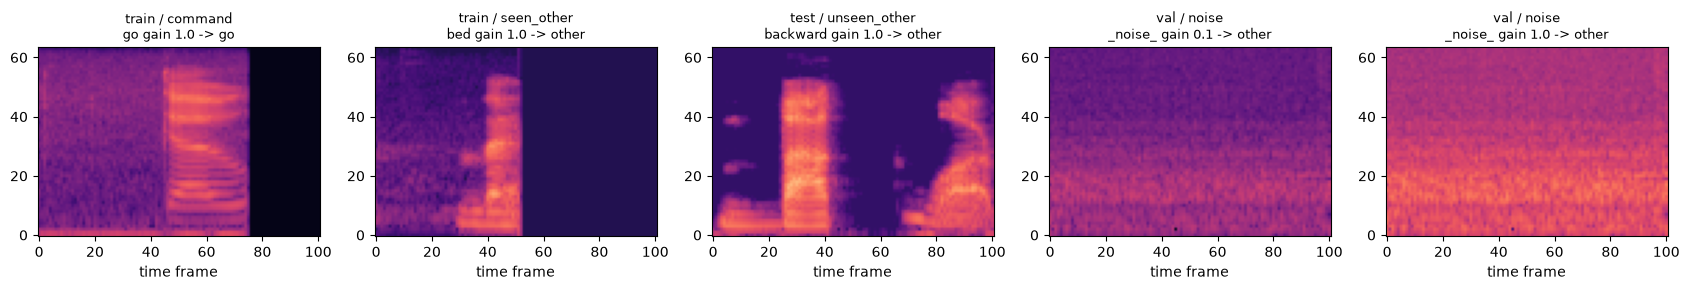

In [5]:
# 셀 5. 녹음 읽기 함수 (이후 노트북에서도 같은 규칙) + 잡음 예시
def load_row(r):
    """목록 한 줄 → 1초 파형 (16,000,). 잡음은 start부터 1초를 잘라 gain을 곱함"""
    if r["group"] == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r["path"]), dtype="float32", start=int(r["start"]), frames=SR)
        x = x * float(r["gain"])
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r["path"]), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64)
to_db = torchaudio.transforms.AmplitudeToDB(top_db=80)
ex = [table[(table.split == "train") & (table.word == "go")].iloc[0],
      table[(table.split == "train") & (table.group == "seen_other")].iloc[0],
      table[(table.split == "test") & (table.group == "unseen_other")].iloc[0],
      table[(table.split == "val") & (table.group == "noise") & (table.gain == 0.1)].iloc[0],
      table[(table.split == "val") & (table.group == "noise") & (table.gain == 1.0)].iloc[0]]
fig, axes = plt.subplots(1, 5, figsize=(17, 3))
for ax, r in zip(axes, ex):
    ax.imshow(to_db(mel(torch.from_numpy(load_row(r)))).numpy(), origin="lower", aspect="auto", cmap="magma", vmin=-80, vmax=40)
    ax.set_title(f"{r['split']} / {r['group']}\n{r['word']} gain {r['gain']} -> {r['label']}", fontsize=9); ax.set_xlabel("time frame")
plt.tight_layout(); plt.show()

In [6]:
# 셀 6. 0번 기준 — 학습 묶음에서 가장 많은 클래스만 고르기 (검증 묶음)
majority = table[table.split == "train"].label.value_counts().idxmax()
val = table[table.split == "val"]
y = val.label.values
acc = np.mean(y == majority)
is_cmd = np.isin(y, COMMANDS)
f1 = []
for c in LABELS:
    tp = np.sum((y == c) & (majority == c)); fp = np.sum((y != c) & (majority == c)); fn = np.sum((y == c) & (majority != c))
    f1.append(0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn))
false_accept = 0.0 if majority == OTHER else 1.0                       # 명령 아닌 소리를 명령으로 판정한 비율
miss = 1.0 if majority == OTHER else np.mean(y[is_cmd] != majority)    # 명령을 놓친 비율
print(f"학습 묶음에서 가장 많은 클래스: {majority} ({(table[table.split == 'train'].label == majority).sum():,}개)")
print(f"0번 기준(검증): 정확도 {acc:.2%}, 매크로 F1 {np.mean(f1):.4f} | 오작동률 {false_accept:.0%}, 놓침률 {miss:.0%}")
print("→ 전부 '명령 아님'이라고 해도 정확도는 이만큼 나오지만, 명령은 하나도 실행하지 못함. 정확도만으로 판단하지 않는 이유")

학습 묶음에서 가장 많은 클래스: other (4,060개)
0번 기준(검증): 정확도 60.61%, 매크로 F1 0.0686 | 오작동률 0%, 놓침률 100%
→ 전부 '명령 아님'이라고 해도 정확도는 이만큼 나오지만, 명령은 하나도 실행하지 못함. 정확도만으로 판단하지 않는 이유
